## Energy Usage chart

To practice data visualisation using Python, I decided to map out our energy usage over the year (using data from our energy supplier) against the maximum and minimum temperatures of the period.

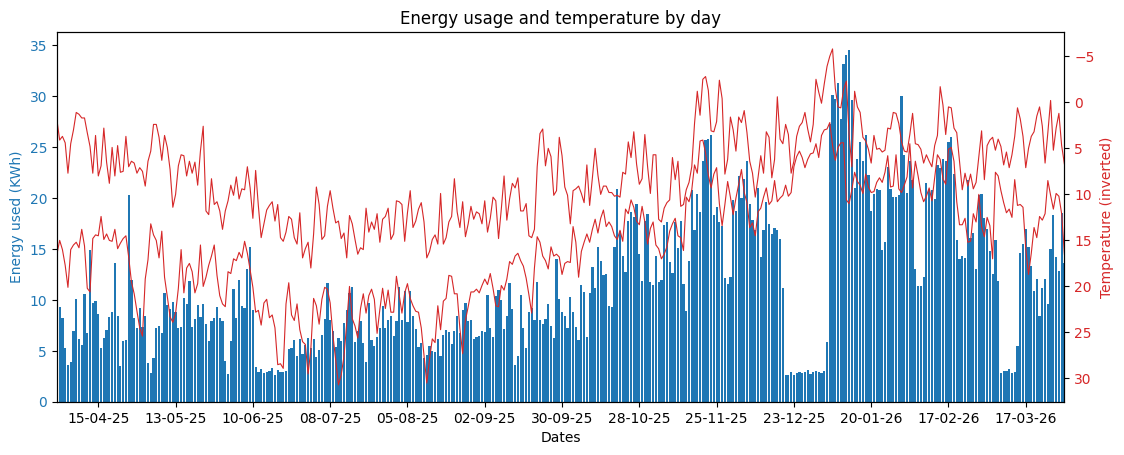

In [15]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd
import numpy as np

#First, I read the csv. It was originally half-hourly but I only needed daily information, so I resampled it. 
def import_from_octopus_csv(octopus_csv_name):
    octopus_data_half_hourly = pd.read_csv(octopus_csv_name,
                               index_col=3,
                               parse_dates=True)
    octopus_data_half_hourly.index = pd.to_datetime(octopus_data_half_hourly.index,yearfirst=True,utc=True)
    octopus_data = octopus_data_half_hourly.resample('D').sum()
    return octopus_data

def label_octopus_dataframe(dataframe_name):
    dates = list(dataframe_name.index)
    energy_used_daily = list(dataframe_name.iloc[:,0])
    return dates, energy_used_daily

#For the maximum and minimum temperatures, I downloaded some publicly-available data
def import_weather_data(weather_csv_name):
    weather_data = pd.read_csv(weather_csv_name,
                               index_col=0,
                               parse_dates=True)
    return weather_data

#I set up the original plot, which I then loaded our energy usage data into
def set_up_plot(x_axis_data,y_axis_data):
    fig = plt.figure()
    axes1 = fig.add_subplot(111)
    axes1.bar(x_axis_data, y_axis_data)
    axes1 = plt.gca()
    axes1.set_xlim(min(x_axis_data), max(x_axis_data))
    return axes1

def set_up_plot_labels_and_titles(figure,date_format,title,x_axis_label,y_axis_label):
    figure_dated = figure.xaxis.set_major_formatter(mdates.DateFormatter(date_format))
    figure.xaxis.set_major_locator(mdates.WeekdayLocator(interval=4))
    color = 'tab:blue'
    figure.set_title(title)
    figure.set_xlabel(x_axis_label)
    figure.set_ylabel(y_axis_label,color=color)
    figure.tick_params(axis='y', labelcolor=color)
    figure.tick_params(axis='x',labelsize=10)
    figure.get_figure().set_figwidth(13)
    return figure

#In order to be able to compare energy usage to the weather, I had to set up a second y-axis and a plot in a different colour
#Note that I invert this axis, because I expect there to be a negative correlation between temperature and energy usage (for heating)
def set_up_second_y_axis(axes1,dates,weather_data,y2_axis_label):
    axes2 = axes1.twinx()
    color = 'tab:red'
    axes2.set_ylabel(f'{y2_axis_label} (inverted)', color=color)
    axes2.plot(dates, weather_data, linewidth=0.8,color=color)
    axes2.tick_params(axis='y', labelcolor=color)
    axes2.yaxis.set_inverted(True)


#Finally, I ran the functions
octopus_data = import_from_octopus_csv(octopus_csv_name="../octopus_data.csv")
x_axis_data,y_axis_data = label_octopus_dataframe(dataframe_name=octopus_data)
weather_data = import_weather_data(weather_csv_name="../temperatures_max_min.csv")
figure = set_up_plot(x_axis_data=x_axis_data,y_axis_data=y_axis_data)
figure_labelled = set_up_plot_labels_and_titles(figure=figure,date_format="%d-%m-%y",title="Energy usage and temperature by day",x_axis_label="Dates",y_axis_label="Energy used (KWh)")
figure_with_second_axis = set_up_second_y_axis(axes1=figure,dates=x_axis_data,weather_data=weather_data,y2_axis_label="Temperature")

plt.show()

<br>
<br>
As expected, there seems to be a negative correlation between outside temperature and energy usage, particularly when the minimum temperature goes towards the region of 5-10 degrees centigrade.

You can clearly see when we went on vacation this year in winter. It's also worth noting that the energy usage lags a day or so behind the temperature, since we need to set our heating plan the evening in advance. I assume this reflects how we'll feel cold one evening and then turn the heating on so we'll be warm the following day